# Chapter 5: How Big Is It?

*Math Class Didn't Show Its Work* by Jason Karpeles

**In this notebook you will** learn to read the size of a number by its place, to say what a grouping or a rounding changed, and to check an estimate against an exact count small enough to do by hand.

The code cells are optional reading. You do not need to run anything or follow the code: the results and the pictures are shown right below each cell. If you do want to peek, each code cell redoes the arithmetic one substitution at a time, the way you would on paper.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
%matplotlib inline

# Colors used in every picture
TEAL = "#1f7a7a"
TERRACOTTA = "#c25b3f"
NAVY = "#24344d"
GOLD = "#d9a441"
LIGHT = "#cfd6dd"
INK = "#1d1d1d"

plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 11})

def fmt(n):
    """Whole number with commas, like 5,084,000."""
    return f"{int(n):,}"

def signed(n):
    """Show a plus sign on positive numbers: +11, -4, 0."""
    return f"+{n}" if n > 0 else str(n)

## Demonstration 1: Compare from the left

**Question in plain words:** Two numerals use almost the same digits, 5,084,000 and 508,400. Which place decides which one is larger?

$$5{,}084{,}000 = 10 \times 508{,}400$$

**What the symbols mean:**
- Each row of the chart is a base-ten place, from millions down to ones.
- A digit's value depends on its row: one row up means ten times as much.
- A $0$ written in a row holds the other digits in their places.
- $\times$ means multiply.

Try to **predict first**: for 640,090 against 604,900, which row will be the first one where the digits differ?

In [2]:
PLACES = ["millions", "hundred-thousands", "ten-thousands", "thousands", "hundreds", "tens", "ones"]

def digits(n):
    return [int(c) for c in f"{n:07d}"]

def compare(first, second):
    d1, d2 = digits(first), digits(second)
    differ = next((i for i in range(7) if d1[i] != d2[i]), None)
    print(f"Compare {fmt(first)} and {fmt(second)}")
    print("  digits of first :", d1)
    print("  digits of second:", d2)
    if differ is None:
        print("  Every place matches, so the numbers are equal.")
        print(f"  {fmt(first)} - {fmt(second)} = {fmt(first - second)}")
    else:
        big = max(first, second)
        print(f"  First unequal place from the left: {PLACES[differ]} ({d1[differ]} against {d2[differ]})")
        print(f"  Larger: {fmt(big)}")
        print(f"  Check by subtraction: {fmt(first)} - {fmt(second)} = {fmt(first - second)}")
    if second and first == 10 * second:
        print(f"  Ten times check: 10 x {fmt(second)} = {fmt(10 * second)}, which matches the first numeral")
    else:
        print(f"  Ten times check: 10 x {fmt(second)} = {fmt(10 * second)}, which is not {fmt(first)}")
    print()

compare(5_084_000, 508_400)
print("Other menu pairs:\n")
for pair in [(640_090, 604_900), (508_400, 58_400), (508_400, 508_400)]:
    compare(*pair)

Compare 5,084,000 and 508,400
  digits of first : [5, 0, 8, 4, 0, 0, 0]
  digits of second: [0, 5, 0, 8, 4, 0, 0]
  First unequal place from the left: millions (5 against 0)
  Larger: 5,084,000
  Check by subtraction: 5,084,000 - 508,400 = 4,575,600
  Ten times check: 10 x 508,400 = 5,084,000, which matches the first numeral

Other menu pairs:

Compare 640,090 and 604,900
  digits of first : [0, 6, 4, 0, 0, 9, 0]
  digits of second: [0, 6, 0, 4, 9, 0, 0]
  First unequal place from the left: ten-thousands (4 against 0)
  Larger: 640,090
  Check by subtraction: 640,090 - 604,900 = 35,190
  Ten times check: 10 x 604,900 = 6,049,000, which is not 640,090

Compare 508,400 and 58,400
  digits of first : [0, 5, 0, 8, 4, 0, 0]
  digits of second: [0, 0, 5, 8, 4, 0, 0]
  First unequal place from the left: hundred-thousands (5 against 0)
  Larger: 508,400
  Check by subtraction: 508,400 - 58,400 = 450,000
  Ten times check: 10 x 58,400 = 584,000, which is not 508,400

Compare 508,400 and 508,400

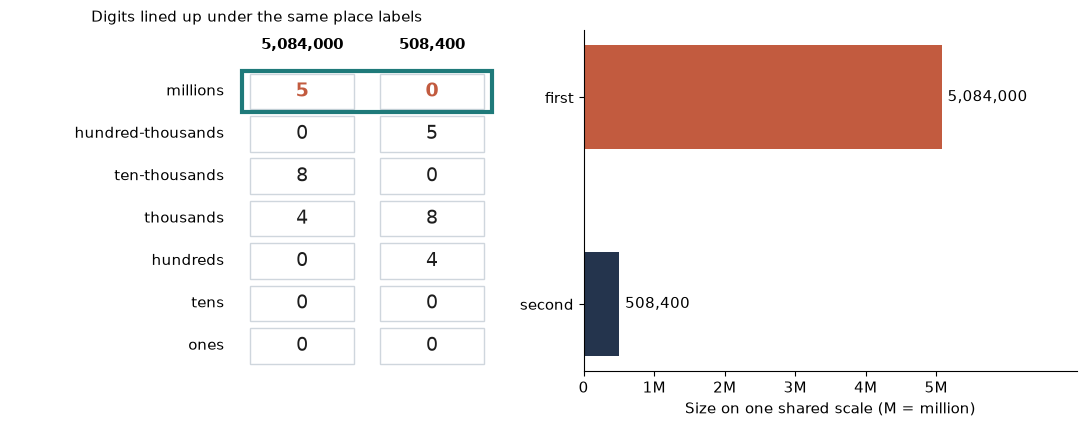

In [3]:
def place_picture(first, second):
    d1, d2 = digits(first), digits(second)
    differ = next((i for i in range(7) if d1[i] != d2[i]), None)
    fig, (ax, bx) = plt.subplots(1, 2, figsize=(11, 4.4))
    for i, place in enumerate(PLACES):
        y = 6 - i
        ax.text(-0.1, y, place, ha="right", va="center")
        for col, d in ((0, d1), (1, d2)):
            ax.add_patch(Rectangle((col + 0.1, y - 0.42), 0.8, 0.84, facecolor="white", edgecolor=LIGHT))
            hot = differ == i
            ax.text(col + 0.5, y, str(d[i]), ha="center", va="center", fontsize=14,
                    color=TERRACOTTA if hot else INK, fontweight="bold" if hot else "normal")
    if differ is not None:
        y = 6 - differ
        ax.add_patch(Rectangle((0.04, y - 0.48), 1.92, 0.96, fill=False, edgecolor=TEAL, linewidth=3))
    ax.text(0.5, 7.0, fmt(first), ha="center", fontweight="bold")
    ax.text(1.5, 7.0, fmt(second), ha="center", fontweight="bold")
    ax.set_xlim(-1.75, 2.05); ax.set_ylim(-0.6, 7.45)
    ax.axis("off")
    ax.set_title("Digits lined up under the same place labels", fontsize=11)
    for row, (n, color) in enumerate(((first, TERRACOTTA), (second, NAVY))):
        y = 1 - row
        bx.barh([y], [n / 1000], color=color, height=0.5)
        bx.text(n / 1000 + 80, y, fmt(n), va="center")
    bx.set_yticks([1, 0]); bx.set_yticklabels(["first", "second"])
    bx.set_xlim(0, 7000)
    bx.set_xticks([0, 1000, 2000, 3000, 4000, 5000]); bx.set_xticklabels(["0", "1M", "2M", "3M", "4M", "5M"])
    bx.set_xlabel("Size on one shared scale (M = million)")
    plt.tight_layout(); plt.show()

place_picture(5_084_000, 508_400)

**What this shows.** Reading from the left, the first row where the digits differ is the millions row (5 against 0), so 5,084,000 is the larger number. One unit in a higher place is worth more than every lower place put together. Here every digit of 508,400 also sits one place to the right of its partner, which is why the first number is exactly ten times the second.

**Where it stops working.** This works for whole numbers written in base ten and lined up by *place*. It fails if you line the numerals up by their first digit instead, or if the two numbers carry different units.

## Demonstration 2: A grouping changes the question

**Question in plain words:** Why do $6 + 4 \times 3$ and $(6 + 4) \times 3$ give different answers?

$$6 + 4 \times 3 \qquad\qquad (6 + 4) \times 3$$

**What the symbols mean:**
- $\times$ means multiply. Parentheses mark a group to calculate first.
- Without parentheses, multiplication is done before addition.
- Without them, only the 4 is repeated: six items, then three groups of four. With them, the whole sum of ten is repeated three times.

**Predict first:** with the parentheses added, how many rows of ten will the picture show?

In [4]:
def grouping(kind, n):
    if kind == "plain":
        mult = 4 * n
        total = 6 + mult
        other = (6 + 4) * n
        print(f"Reading: six plus {n} groups of four")
        print(f"  6 + 4 x {n} = 6 + {mult} = {total}")
        print(f"  The other grouping: (6 + 4) x {n} = 10 x {n} = {other}")
    else:
        total = (6 + 4) * n
        other = 6 + 4 * n
        print(f"Reading: ten, repeated {n} times")
        print(f"  (6 + 4) x {n} = 10 x {n} = {total}")
        print(f"  The other grouping: 6 + 4 x {n} = 6 + {4 * n} = {other}")
    print()
    return total

grouping("plain", 3)
print("Other menu values:\n")
grouping("grouped", 3)
grouping("plain", 5)
grouping("grouped", 5)

Reading: six plus 3 groups of four
  6 + 4 x 3 = 6 + 12 = 18
  The other grouping: (6 + 4) x 3 = 10 x 3 = 30

Other menu values:

Reading: ten, repeated 3 times
  (6 + 4) x 3 = 10 x 3 = 30
  The other grouping: 6 + 4 x 3 = 6 + 12 = 18

Reading: six plus 5 groups of four
  6 + 4 x 5 = 6 + 20 = 26
  The other grouping: (6 + 4) x 5 = 10 x 5 = 50

Reading: ten, repeated 5 times
  (6 + 4) x 5 = 10 x 5 = 50
  The other grouping: 6 + 4 x 5 = 6 + 20 = 26



50

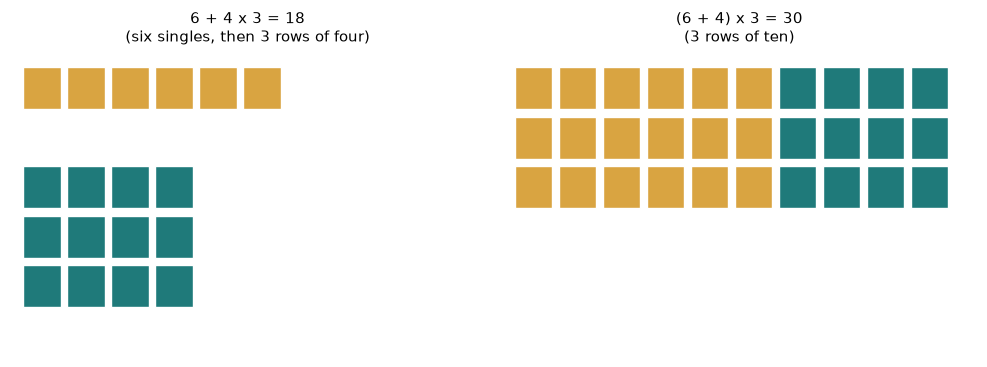

In [5]:
def square_grid(ax, items, cols, y0, color):
    """Draw items as small squares in rows of `cols`, top row first."""
    for k in range(items):
        r, c = divmod(k, cols)
        ax.add_patch(Rectangle((c, y0 - r), 0.85, 0.85, facecolor=color, edgecolor="white"))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
n = 3
ax = axes[0]
square_grid(ax, 6, 6, 4, GOLD)                  # the six single items
for r in range(n):                              # n groups of four
    for c in range(4):
        ax.add_patch(Rectangle((c, 2 - r), 0.85, 0.85, facecolor=TEAL, edgecolor="white"))
ax.set_xlim(-0.3, 10.5); ax.set_ylim(-1, 5.2); ax.axis("off")
ax.set_title(f"6 + 4 x {n} = {6 + 4 * n}\n(six singles, then {n} rows of four)", fontsize=11)

ax = axes[1]
for r in range(n):
    for c in range(10):
        ax.add_patch(Rectangle((c, 4 - r), 0.85, 0.85, facecolor=TEAL if c >= 6 else GOLD, edgecolor="white"))
ax.set_xlim(-0.3, 10.5); ax.set_ylim(-1, 5.2); ax.axis("off")
ax.set_title(f"(6 + 4) x {n} = {(6 + 4) * n}\n({n} rows of ten)", fontsize=11)
plt.tight_layout(); plt.show()

**What this shows.** In the default reading, $6 + 4 \times 3 = 6 + 12 = 18$. Multiplication comes before addition unless parentheses group the sum first. With the parentheses the picture has 3 rows of ten, 30 squares, a different question with a different answer.

**Where it stops working.** This is the ordinary order of operations: groups first, then multiplication, then addition (no exponents appear here). Reading a line strictly left to right would give $(6 + 4) \times 3$ even without parentheses, which is a different instruction.

## Demonstration 3: The example theater

**Question in plain words:** Rounding 18 rows of 28 seats up to 20 rows of 30 gives 600. How far off is that, and in which direction?

$$18 \times (30 - 2) = 504$$

**What the symbols mean:**
- Rows and seats per row are the two factors; their product counts seats.
- The teal rectangle is the supplied plan (18 by 28). The hatched rectangle is a rounded model.
- Writing 28 as $30 - 2$ lets you multiply by a friendly number, then take away the extra.

**Predict first:** if only the seats per row are rounded, from 28 up to 30, will the estimate still be high?

In [6]:
def theater(rows, seats, exact_rows=18, exact_seats=28):
    exact = exact_rows * exact_seats
    est = rows * seats
    print(f"Rounded model: {rows} x {seats} = {est} seats")
    base = exact_rows * 30
    print(f"Exact by compensation: {exact_rows} x 28 = {exact_rows} x (30 - 2) = {base} - {exact_rows} x 2 = {base} - {exact_rows * 2} = {base - exact_rows * 2} seats")
    diff = est - exact
    print(f"Estimate minus exact: {est} - {exact} = {diff}")
    moved = [("rows", rows - exact_rows), ("seats", seats - exact_seats)]
    if all(m >= 0 for _, m in moved) and any(m > 0 for _, m in moved):
        print("Both factors moved up or stayed, so we predicted HIGH.")
    elif all(m <= 0 for _, m in moved) and any(m < 0 for _, m in moved):
        print("Both factors moved down or stayed, so we predicted LOW.")
    else:
        print("No factor changed, so the estimate is exact." if diff == 0 else "Mixed directions: not settled by the arrows.")
    print(f"Result: {abs(diff)} seats {'high' if diff > 0 else 'low' if diff < 0 else 'off (exact)'}")
    print()

theater(20, 30)
print("Other menu values:\n")
theater(18, 30)
theater(18, 28)

Rounded model: 20 x 30 = 600 seats
Exact by compensation: 18 x 28 = 18 x (30 - 2) = 540 - 18 x 2 = 540 - 36 = 504 seats
Estimate minus exact: 600 - 504 = 96
Both factors moved up or stayed, so we predicted HIGH.
Result: 96 seats high

Other menu values:

Rounded model: 18 x 30 = 540 seats
Exact by compensation: 18 x 28 = 18 x (30 - 2) = 540 - 18 x 2 = 540 - 36 = 504 seats
Estimate minus exact: 540 - 504 = 36
Both factors moved up or stayed, so we predicted HIGH.
Result: 36 seats high

Rounded model: 18 x 28 = 504 seats
Exact by compensation: 18 x 28 = 18 x (30 - 2) = 540 - 18 x 2 = 540 - 36 = 504 seats
Estimate minus exact: 504 - 504 = 0
No factor changed, so the estimate is exact.
Result: 0 seats off (exact)



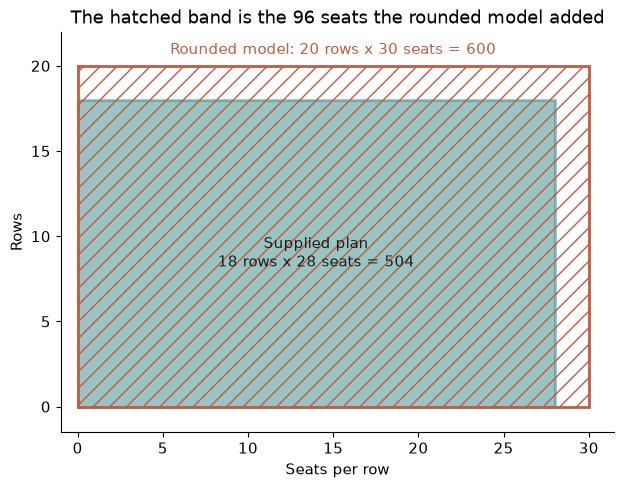

In [7]:
fig, ax = plt.subplots(figsize=(7.5, 5.2))
ax.add_patch(Rectangle((0, 0), 28, 18, facecolor=TEAL, alpha=0.45, edgecolor=TEAL, linewidth=2))
ax.add_patch(Rectangle((0, 0), 30, 20, fill=False, hatch="//", edgecolor=TERRACOTTA, linewidth=2))
ax.text(14, 9, "Supplied plan\n18 rows x 28 seats = 504", ha="center", va="center", fontsize=11, color=INK)
ax.text(15, 20.7, "Rounded model: 20 rows x 30 seats = 600", ha="center", color=TERRACOTTA)
ax.set_xlim(-1, 31.5); ax.set_ylim(-1.5, 22)
ax.set_aspect("equal"); ax.set_xlabel("Seats per row"); ax.set_ylabel("Rows")
ax.set_title("The hatched band is the 96 seats the rounded model added")
plt.show()

**What this shows.** Rounding a positive factor up makes the rectangle bigger, so the product grows. Every rounded factor moved up, so the estimate was predicted high, and it is 96 seats high (600 against 504). When you estimate a total, write the rounded factors and their direction beside the result so anyone can see why it is high or low.

**Where it stops working.** Every row must have the same number of seats and both factors must be positive. If one factor moved up and the other down, the direction could not be predicted from the rounding alone (that is the next demonstration).

## Demonstration 4: Which way does the estimate miss?

**Question in plain words:** The tile display has 13 rows of 19. When can you tell, before multiplying, whether an estimate is high or low?

$$13 \times 19 = 13 \times (20 - 1)$$

**What the symbols mean:**
- Each rounded factor moves up, moves down, or is kept.
- The gold bar is the estimate; the teal bar is the exact count of 247 tiles.
- If every move is up or kept, the product can only grow. If every move is down or kept, it can only shrink. One up and one down can pull either way.

**Predict first:** using 15 rows and 20 tiles per row, will the estimate land above 247 or below it?

In [8]:
def tiles(rows, per_row):
    exact = 13 * 19
    est = rows * per_row
    arrows = []
    for name, new, old in (("rows", rows, 13), ("tiles per row", per_row, 19)):
        arrows.append("up" if new > old else "down" if new < old else "kept")
    print(f"Rounded rows {rows} ({arrows[0]}), rounded tiles per row {per_row} ({arrows[1]})")
    print(f"  Estimate: {rows} x {per_row} = {est} tiles")
    print(f"  Exact: 13 x 19 = 13 x (20 - 1) = {13 * 20} - 13 = {exact} tiles")
    diff = est - exact
    print(f"  Estimate minus exact: {est} - {exact} = {diff}")
    ups, downs = "up" in arrows, "down" in arrows
    if ups and downs:
        pred = "not settled by the arrows"
    elif ups:
        pred = "high"
    elif downs:
        pred = "low"
    else:
        pred = "exact"
    actual = "exact" if diff == 0 else f"{'high' if diff > 0 else 'low'} by {abs(diff)}"
    print(f"  Predicted before multiplying: {pred}")
    print(f"  Actual: {actual}")
    print()
    return est

tiles(10, 20)
print("Other menu values:\n")
for r, p in [(10, 19), (13, 20), (13, 19), (15, 20), (15, 19)]:
    tiles(r, p)

Rounded rows 10 (down), rounded tiles per row 20 (up)
  Estimate: 10 x 20 = 200 tiles
  Exact: 13 x 19 = 13 x (20 - 1) = 260 - 13 = 247 tiles
  Estimate minus exact: 200 - 247 = -47
  Predicted before multiplying: not settled by the arrows
  Actual: low by 47

Other menu values:

Rounded rows 10 (down), rounded tiles per row 19 (kept)
  Estimate: 10 x 19 = 190 tiles
  Exact: 13 x 19 = 13 x (20 - 1) = 260 - 13 = 247 tiles
  Estimate minus exact: 190 - 247 = -57
  Predicted before multiplying: low
  Actual: low by 57

Rounded rows 13 (kept), rounded tiles per row 20 (up)
  Estimate: 13 x 20 = 260 tiles
  Exact: 13 x 19 = 13 x (20 - 1) = 260 - 13 = 247 tiles
  Estimate minus exact: 260 - 247 = 13
  Predicted before multiplying: high
  Actual: high by 13

Rounded rows 13 (kept), rounded tiles per row 19 (kept)
  Estimate: 13 x 19 = 247 tiles
  Exact: 13 x 19 = 13 x (20 - 1) = 260 - 13 = 247 tiles
  Estimate minus exact: 247 - 247 = 0
  Predicted before multiplying: exact
  Actual: exact

R

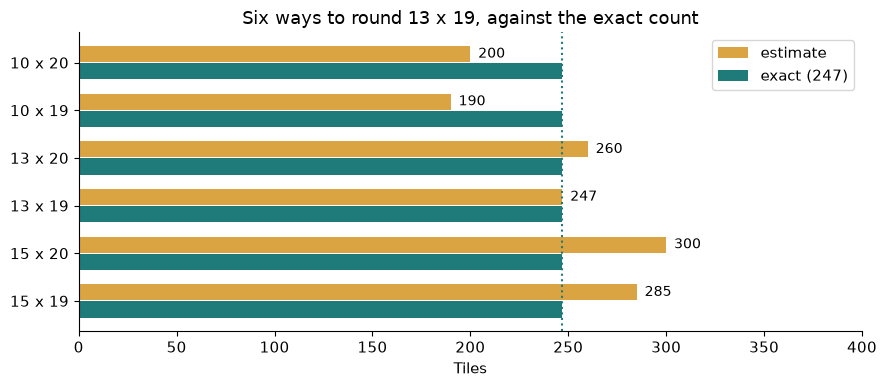

In [9]:
states = [(10, 20), (10, 19), (13, 20), (13, 19), (15, 20), (15, 19)]
labels = [f"{r} x {p}" for r, p in states]
ests = [r * p for r, p in states]
fig, ax = plt.subplots(figsize=(9, 4))
y = np.arange(len(states))[::-1]
ax.barh(y + 0.18, ests, height=0.34, color=GOLD, label="estimate")
ax.barh(y - 0.18, [247] * len(states), height=0.34, color=TEAL, label="exact (247)")
for yy, e in zip(y, ests):
    ax.text(e + 4, yy + 0.18, str(e), va="center", fontsize=10)
ax.set_yticks(y); ax.set_yticklabels(labels)
ax.axvline(247, color=TEAL, linestyle=":")
ax.set_xlabel("Tiles"); ax.set_xlim(0, 400)
ax.set_title("Six ways to round 13 x 19, against the exact count")
ax.legend(loc="upper right")
plt.tight_layout(); plt.show()

**What this shows.** With 10 rows and 20 tiles per row, the estimate is $10 \times 20 = 200$ and the exact count is $13 \times (20 - 1) = 260 - 13 = 247$, so the estimate is 47 tiles low. One factor moved down and one moved up, so the arrows alone could not predict the direction. Mark an arrow beside each rounded factor: if the arrows agree, say high or low before you multiply exactly; if they disagree, say the direction is not settled.

**Where it stops working.** The rule needs two positive factors and a stated rounding for each. It says nothing about *how large* the miss is, and it fails for mixed directions.

## Practice

**1.** Which is larger, 3,402,000 or 3,420,000, and which place decides it?

<details><summary>Show answer</summary>

Both have 3 millions and 4 hundred-thousands. In the ten-thousands place, 2 beats 0, so 3,420,000 is larger.
Check: 3,420,000 - 3,402,000 = 18,000.

</details>

**2.** What are $50 - 6 \times 7$ and $(50 - 6) \times 7$?

<details><summary>Show answer</summary>

50 - 6 x 7 = 50 - 42 = 8.
(50 - 6) x 7 = 44 x 7 = 308.

</details>

**3.** A room has 17 rows of 26 chairs. Rounding to 20 x 30, is the estimate high or low, and by how much?

<details><summary>Show answer</summary>

20 x 30 = 600 chairs, predicted high because both factors went up.
Exact: 17 x 26 = 17 x (30 - 4) = 510 - 68 = 442.
600 - 442 = 158, so the estimate is 158 chairs high.

</details>

**4.** Estimate 42 boxes of 47 cards as 40 x 50. Can you predict the direction, and what is the miss?

<details><summary>Show answer</summary>

No: 42 went down and 47 went up, so the arrows disagree.
40 x 50 = 2,000 and 42 x 47 = 42 x (50 - 3) = 2,100 - 126 = 1,974.
The estimate is 2,000 - 1,974 = 26 cards high.

</details>